In [1]:
import sys

sys.path.append(
    "/home/main/Projects/2026/DEC/ome-tiff-processing/src/ome_tiff_processing"
)

from image.image import OmeTiffFile

In [25]:
import zarr
import tifffile
import xmltodict

# from typing import tuple



class OmeTiffFile:

    def __init__(self, filepath: str):
        self._filepath = filepath
        self.tif = tifffile.TiffFile(self._filepath)

        self.images = {
            series_id: OmeTiffImage(series_data)
            for series_id, series_data 
            in enumerate(self.tif.series)
        }

    def sel(
        self, 
        image,
        layer,
        xbounds: tuple[int],
        ybounds: tuple[int],
    ):
        # check we're working with an actual image
        assert self.images[image]
        assert self.images[image].layers[layer]

class OmeTiffImage:

    def __init__(self, series: tifffile.TiffPageSeries):
        self._series = series
        self.store = zarr.open(
            self._series.levels[0].aszarr(), 
            mode="r"
        )

        # We need to handle both single layer and multi-layer
        # instances, we'll just handle them here as two explicit
        # cases.
        self.layers = {}

        if isinstance(self.store, zarr.Array):
            self.layers[0] = self.store

        elif isinstance(self.store, zarr.Group):
            for level_id, level_data in self.store.arrays():
                self.layers[int(level_id)] = level_data

In [27]:
image = OmeTiffFile("/home/main/Projects/2026/DEC/ome-tiff-processing/data/multi-channel_439_167_5_3_1.ome.tif")
image = OmeTiffFile("/home/main/Projects/2026/DEC/ome-tiff-processing/data/Leica1_36832_38432_1_3_1.ome.tiff")

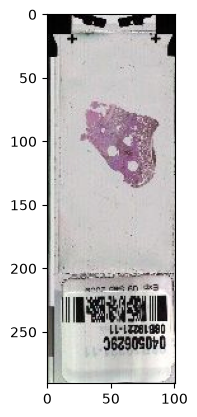

In [45]:
import matplotlib.pyplot as plt

plt.imshow(
    image.images[0].layers[2][:].transpose(1, 2, 0)
)